[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.2/Problem_2.6.ipynb)

# Chapter 2, Problem 6 — drawing basis vectors of three frames

**Problem (paraphrased).** In the $t$–$x$ spacetime diagram of $\mathcal O$, draw the basis vectors $\vec e_0$ and $\vec e_1$. Draw the corresponding basis vectors of the frame $\bar{\mathcal O}$ that moves with speed 0.6 in the $+x$ direction relative to $\mathcal O$. Draw the corresponding basis vectors of a frame $\bar{\bar{\mathcal O}}$ that moves with speed 0.6 in the $+x$ direction relative to $\bar{\mathcal O}$.

## Step 1 — $\mathcal O$'s basis

By definition (Eq. 2.9), $\vec e_0 \xrightarrow{\mathcal O}(1, 0)$ and $\vec e_1 \xrightarrow{\mathcal O}(0, 1)$ in $(t, x)$: unit arrows along $\mathcal O$'s $t$ and $x$ axes.

## Step 2 — $\bar{\mathcal O}$'s basis, $v = 0.6$

$\gamma = 1/\sqrt{1-0.36} = 1/0.8 = 1.25$, $\gamma v = 0.75$.

**Shortcut.** $\vec e_{\bar0}$ is the four-velocity of $\bar{\mathcal O}$ (§2.3). In $\mathcal O$ it has components $\gamma(1, v)$. $\vec e_{\bar1}$ is the unit vector along $\bar{\mathcal O}$'s $\bar x$ axis ($t = vx$), so it is $\gamma(v, 1)$.

**Formally,** from Eq. (2.15), $\vec e_{\bar\mu} = \Lambda^\nu{}_{\bar\mu}(-v)\,\vec e_\nu$. The components of $\vec e_{\bar\mu}$ in $\mathcal O$ are the columns of the inverse matrix $\Lambda(-v)$:
$$
\Lambda(-v) = \begin{pmatrix}\gamma & \gamma v\\ \gamma v & \gamma\end{pmatrix} = \begin{pmatrix}1.25 & 0.75\\ 0.75 & 1.25\end{pmatrix}
\quad\Rightarrow\quad
\vec e_{\bar0} \xrightarrow{\mathcal O}(1.25,\ 0.75),\qquad \vec e_{\bar1} \xrightarrow{\mathcal O}(0.75,\ 1.25).
$$

## Step 3 — $\bar{\bar{\mathcal O}}$'s basis, 0.6 relative to $\bar{\mathcal O}$

**Velocity relative to $\mathcal O$** (Eq. 1.13): $w = \dfrac{0.6 + 0.6}{1 + 0.36} = \dfrac{1.2}{1.36} = \dfrac{15}{17} \approx 0.882$. Then $\gamma_w = 1/\sqrt{1 - 225/289} = 17/8 = 2.125$ and $\gamma_w w = 15/8 = 1.875$:
$$
\vec e_{\bar{\bar0}} \xrightarrow{\mathcal O}(2.125,\ 1.875),\qquad \vec e_{\bar{\bar1}} \xrightarrow{\mathcal O}(1.875,\ 2.125).
$$
Same answer by composing transformations: $\Lambda(\mathcal O\to\bar{\bar{\mathcal O}}) = \Lambda(0.6)\Lambda(0.6)$ (Problem 13), whose inverse has these columns.

**Equivalently with rapidities** (Problem 1.18): each step is $u = \tanh^{-1}0.6 = \ln 2 \approx 0.693$. Two steps give $2\ln2 = \ln4$, so $\cosh = (4 + 1/4)/2 = 2.125$ ✓, $\sinh = (4 - 1/4)/2 = 1.875$ ✓.

## What the picture shows

(In the plot the double-barred frame is labelled **Ō′**, since a double bar doesn't render reliably in figure text.)

- Every $\vec e_0$-type arrow ends on the hyperbola $t^2 - x^2 = 1$, and every $\vec e_1$-type arrow ends on $x^2 - t^2 = 1$: they are all unit vectors ($\vec e_0\cdot\vec e_0 = -1$, $\vec e_1\cdot\vec e_1 = +1$, §2.5). They *look* longer on paper as the speed increases.
- Each pair is placed symmetrically about the light ray $t = x$. That's how orthogonality ($\vec e_{\bar0}\cdot\vec e_{\bar1} = 0$) looks in a spacetime diagram (§2.5, Fig. 2.4).
- The faster frame's pair is squeezed closer to the light cone.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

In [2]:
import numpy as np
import sympy as sp
from schutz_gr import boost_matrix, minkowski_dot
from schutz_gr.diagrams import SpacetimeDiagram, COLORS
%config InlineBackend.figure_format = 'retina'

frames = {"O": np.eye(4), "Ō": boost_matrix(0.6), "Ō′": boost_matrix(0.6) @ boost_matrix(0.6)}   # Ō′ = Schutz's double-barred frame
basis = {}
for name, L in frames.items():
    Linv = np.linalg.inv(L)                  # columns = components in O of that frame's basis vectors
    e0, e1 = Linv[:, 0], Linv[:, 1]
    basis[name] = (e0, e1)
    print(f"{name:3s}: e0 → (t, x) = ({e0[0]:.4f}, {e0[1]:.4f}),  e1 → ({e1[0]:.4f}, {e1[1]:.4f})"
          f"   e0·e0 = {minkowski_dot(e0, e0):+.3f}, e1·e1 = {minkowski_dot(e1, e1):+.3f}, e0·e1 = {minkowski_dot(e0, e1):+.1e}")
print("velocity of Ō′ (double-barred frame) relative to O:", sp.nsimplify((0.6 + 0.6) / (1 + 0.36)))

O  : e0 → (t, x) = (1.0000, 0.0000),  e1 → (0.0000, 1.0000)   e0·e0 = -1.000, e1·e1 = +1.000, e0·e1 = +0.0e+00
Ō  : e0 → (t, x) = (1.2500, 0.7500),  e1 → (0.7500, 1.2500)   e0·e0 = -1.000, e1·e1 = +1.000, e0·e1 = +1.1e-16
Ō′ : e0 → (t, x) = (2.1250, 1.8750),  e1 → (1.8750, 2.1250)   e0·e0 = -1.000, e1·e1 = +1.000, e0·e1 = +0.0e+00
velocity of Ō′ (double-barred frame) relative to O: 15/17


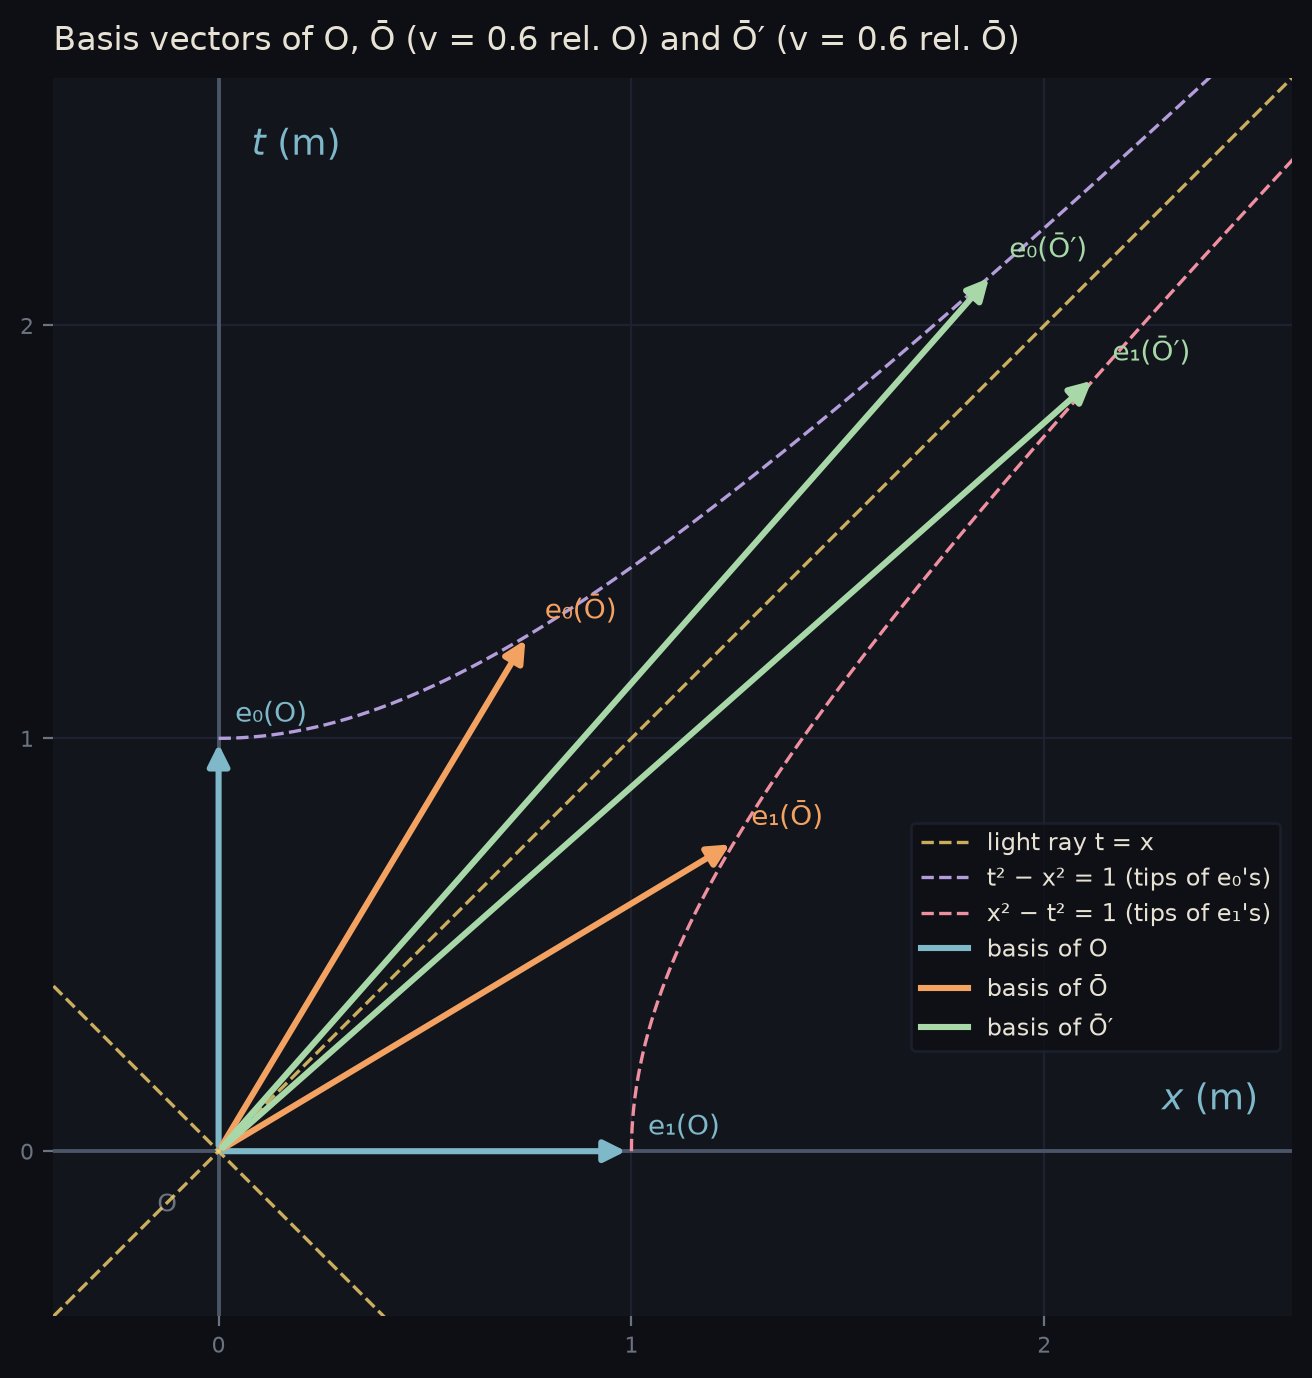

In [3]:
d = SpacetimeDiagram(xlim=(-0.4, 2.6), tlim=(-0.4, 2.6), title="Basis vectors of O, Ō (v = 0.6 rel. O) and Ō′ (v = 0.6 rel. Ō)", size=7)
d.light_cone(label="light ray t = x", color="gold", shade=False)
X = np.linspace(0, 2.6, 300)
d.line(X, np.sqrt(1 + X**2), color="violet", lw=1.2, ls="--", label="t² − x² = 1 (tips of e₀'s)")
d.line(np.sqrt(1 + X**2), X, color="rose", lw=1.2, ls="--", label="x² − t² = 1 (tips of e₁'s)")
colors = {"O": "teal", "Ō": "amber", "Ō′": "green"}
for name, (e0, e1) in basis.items():
    c = COLORS[colors[name]]
    for vec, lab in ((e0, "e₀"), (e1, "e₁")):
        d.ax.annotate("", xy=(vec[1], vec[0]), xytext=(0, 0),
                      arrowprops=dict(arrowstyle="-|>", color=c, lw=2.2, mutation_scale=16), zorder=5)
        d.ax.text(vec[1] + 0.04, vec[0] + 0.04, f"{lab}({name})", color=c, fontsize=10, zorder=6)
    d.ax.plot([], [], color=c, lw=2.2, label=f"basis of {name}")
    d._legend_handles.append(d.ax.lines[-1])
d.show(loc="lower right", bbox_to_anchor=(1.0, 0.205))